In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile , os

base_path = '/content/drive/MyDrive/emotion-detection'

with zipfile.ZipFile(os.path.join(base_path , 'data/raw/archive.zip') , 'r') as zip_ref :
  zip_ref.extractall('/content')

In [3]:
for root , dirs , files in os.walk('/content/archive') :
  level = root.replace('/content/' , '' ).count(os.sep)
  indent = ' ' * 2 * level
  print(f'{indent}{os.path.basename(root)}/')
  if level == 2 :
    for file in files[:3] :
      sub_indent = indent * 3
      print(f'{sub_indent}{file}')


archive/
  train/
    angry/
            aug_321741.png
            train_01182_aligned.jpg
            aug_529014.png
    fear/
            aug_162975.png
            aug_963594.png
            aug_575332.png
    surprise/
            aug_137920.png
            aug_949578.png
            train_08350_aligned.jpg
    disgust/
            aug_313113.png
            aug_914081.png
            aug_572158.png
    happy/
            train_08459_aligned.jpg
            train_02185_aligned.jpg
            aug_185189.png
    sad/
            aug_848981.png
            aug_195616.png
            aug_278901.png
    neutral/
            train_10340_aligned.jpg
            train_09769_aligned.jpg
            train_12045_aligned.jpg
  val/
    angry/
            aug_256157.png
            aug_117505.png
            aug_415868.png
    fear/
            aug_314069.png
            aug_347042.png
            aug_898324.png
    surprise/
            aug_668034.png
            aug_244462.png
            a

## Chargement des données

Le dataset est organisé en trois splits (train, val, test), chacun contenant
un sous-dossier par émotion. `image_dataset_from_directory` parcourt cette
structure, trie les classes alphabétiquement pour leur assigner un indice fixe,
puis construit une liste de chemins mélangés pour éviter de biaiser le modèle.

Les images ne sont pas chargées en mémoire à ce stade — Keras prépare uniquement
le plan de lecture. Chaque image sera lue, décodée, redimensionnée en 48×48
et convertie en niveaux de gris uniquement quand `model.fit` en aura besoin.
Les labels sont encodés automatiquement en one-hot pour correspondre à
`categorical_crossentropy`.

In [4]:
import tensorflow as tf

dataset_path = '/content/archive'

train_ds = tf.keras.utils.image_dataset_from_directory(
    f'{dataset_path}/train',
    image_size = (75,75) ,
    color_mode = 'grayscale',
    batch_size = 64 ,
    shuffle =True ,
    label_mode = "categorical"
)
print("Classes :", train_ds.class_names)

Found 30023 files belonging to 7 classes.
Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [5]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    f'{dataset_path}/val',
    image_size=(75,75),
    color_mode='grayscale',
    batch_size=64,
    shuffle=False,            # pas besoin de mélanger pour la validation
    label_mode='categorical'
)
print("Classes :", train_ds.class_names)

Found 7504 files belonging to 7 classes.
Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [6]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    f'{dataset_path}/test',
    image_size=(75,75),
    color_mode='grayscale',
    batch_size=64,
    shuffle=False,
    label_mode='categorical'
)
print("Classes :", train_ds.class_names)

Found 4165 files belonging to 7 classes.
Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## Normalisation

Les pixels sortent du chargement avec des valeurs entre 0 et 255.
On les ramène entre 0 et 1 en divisant par 255. Cette étape est importante
pour stabiliser l'entraînement — des valeurs trop grandes rendent les gradients
instables et ralentissent la convergence.

L'ordre exact est :
1. Lit 64 images depuis le disque
2. Pour chaque image :
     * décode le fichier (jpg/png)
     * redimensionne en (48×48)
     * convertit en grayscale
3. Constitue le tenseur brut (64, 48, 48, 1) pixels entre 0-255
4. Encode les labels en one-hot → (64, 7)
5. .map() intercepte le batch
     → applique la normalisation ÷255 sur le tenseur
     → retourne (64, 48, 48, 1) pixels entre 0-1
6. Livre le batch normalisé au modèle

In [7]:
# Normalisation [0, 255] → [0, 1]
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds   = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds  = test_ds.map(lambda x, y: (normalization_layer(x), y))

## Optimisation du pipeline — Prefetch et AUTOTUNE

Sans prefetch, le GPU et le CPU travaillent en séquentiel :
le GPU attend à chaque fois que le CPU finisse de préparer le batch suivant
avant de pouvoir continuer.


* Sans prefetch :

    CPU prépare batch 1 → GPU traite batch 1 → CPU prépare batch 2 → GPU traite batch 2
    (GPU attend à chaque fois)

* Avec prefetch :

  le CPU et le GPU travaillent en parallèle — pendant que
  le GPU traite le batch courant, le CPU prépare déjà le batch suivant.

AUTOTUNE observe les ressources disponibles (RAM, CPU) et décide
dynamiquement de la taille optimale de cette file — plus de RAM disponible,
plus la file est grande, plus le GPU a de batchs en avance sans jamais attendre.

Le buffer fonctionne comme une file d'attente :
- Au départ le CPU remplit le buffer avec plusieurs batchs
- Quand le GPU consomme un batch, la place libérée est immédiatement
  occupée par un nouveau batch préparé par le CPU
- Le buffer maintient toujours le même nombre de batchs en attente

## Choix entre Prefetch et Autotune
Avec ces chiffres :

    Train  : 30 023 images × 48 × 48 × 1 ≈ 66 MB

    Val    :  7 504 images × 48 × 48 × 1 ≈ 16 MB

    Test   :  4 165 images × 48 × 48 × 1 ≈  9 MB

    ─────────────────────────────────────────────
    Total  :                               ≈ 91 MB


91 MB c'est très léger — Colab a généralement 12 GB de RAM disponible. Donc le cache est parfaitement adapté ici.

Epoch 1 :

    CPU prépare b1 → stocke en cache → met dans buffer

    CPU prépare b2 → stocke en cache → met dans buffer

    CPU prépare b3 → stocke en cache → met dans buffer

    Buffer : [b1, b2, b3]  ← AUTOTUNE a décidé N=3

    GPU prend b1 :

      Buffer : [b2, b3, __]
      CPU prépare b4 → stocke en cache → met dans buffer
      Buffer : [b2, b3, b4]

    GPU prend b2 :

      Buffer : [b3, b4, __]
      CPU prépare b5 → stocke en cache → met dans buffer
      Buffer : [b3, b4, b5]

Epoch 2 :

    CPU lit b1 depuis cache RAM → met dans buffer  (pas de lecture disque)
    CPU lit b2 depuis cache RAM → met dans buffer
    ...

In [8]:
# AUTOTUNE : demande à TensorFlow de décider lui-même combien de batchs
# stocker dans le buffer selon les ressources disponibles (RAM, CPU)
AUTOTUNE = tf.data.AUTOTUNE

# cache()    : stocke chaque batch en RAM au fur et à mesure de la première epoch
#              disque → cache → buffer → GPU (epoch 1)
#              cache RAM → buffer → GPU      (epochs suivantes)
# prefetch() : maintient un buffer tournant de N batchs prêts à consommer
#              pendant que le GPU traite un batch, le CPU prépare le suivant
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

In [9]:
from tensorflow.keras import layers, models

def build_emotion_cnn(input_shape=(75, 75, 1), num_classes=7):
    """
    Construit le modèle CNN pour la classification d'émotions.

    Args:
        input_shape (tuple): Dimensions d'une image d'entrée.
                             Par défaut (75, 75, 1) = image 75×75 en niveaux de gris.
        num_classes (int): Nombre de classes à prédire.

    Returns:
        tf.keras.Sequential: Modèle CNN.
    """

    model = models.Sequential([

        # ────────────────────────────────────────────────────────────────
        # BLOC 1
        # Entrée : (75, 75, 1)
        # Sortie après pooling : (37, 37, 32)
        # ────────────────────────────────────────────────────────────────

        layers.Conv2D(
            32,
            (3, 3),
            padding='same',
            input_shape=input_shape
        ),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),
        layers.Dropout(0.25),

        # ────────────────────────────────────────────────────────────────
        # BLOC 2
        # Entrée : (37, 37, 32)
        # Sortie après pooling : (18, 18, 64)
        # ────────────────────────────────────────────────────────────────

        layers.Conv2D(
            64,
            (3, 3),
            padding='same'
        ),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),
        layers.Dropout(0.25),

        # ────────────────────────────────────────────────────────────────
        # BLOC 3
        # Entrée : (18, 18, 64)
        # Sortie après pooling : (9, 9, 128)
        # ────────────────────────────────────────────────────────────────

        layers.Conv2D(
            128,
            (3, 3),
            padding='same'
        ),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),
        layers.Dropout(0.25),

        # ────────────────────────────────────────────────────────────────
        # BLOC 4
        # Entrée : (9, 9, 128)
        # Sortie après pooling : (4, 4, 256)
        # ────────────────────────────────────────────────────────────────

        layers.Conv2D(
            256,
            (3, 3),
            padding='same'
        ),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),
        layers.Dropout(0.25),

        # ────────────────────────────────────────────────────────────────
        # CLASSIFIEUR
        # (4, 4, 256) → 4096
        # ────────────────────────────────────────────────────────────────

        layers.Flatten(),

        layers.Dense(
            512,
            activation='relu'
        ),

        layers.BatchNormalization(),

        layers.Dropout(0.5),

        layers.Dense(
            num_classes,
            activation='softmax'
        )
    ])

    return model

In [10]:
model = build_emotion_cnn()

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 75, 75, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 75, 75, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 37, 37, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 18, 18, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 18, 18, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 9, 9, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 9, 9, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,04

 Total params: 2,493,063 (9.51 MB)

 Trainable params: 2,491,079 (9.50 MB)

 Non-trainable params: 1,984 (7.75 KB)

In [11]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## Le déroulement complet pour chaque batch

1. Forward pass (64 images en parallèle)

     → 64 prédictions

2. Loss function

     → calcule l'erreur pour chacune des 64 images

     → moyenne des 64 erreurs = loss du batch

3. Accuracy
     → compte combien de prédictions correctes sur 64

     → ex: 40/64 = 0.625

4. Backward pass (backpropagation)

     → calcule le gradient de chaque poids

5. Adam

     → ajuste les poids selon les gradients

6. Batch suivant → poids déjà mis à jour

## À la fin de l'epoch

* loss moyenne     = moyenne des 470 loss de chaque batch
* accuracy moyenne = moyenne des 470 accuracy de chaque batch

* 470/470 — 0s    - accuracy: 0.3175  ← accuracy du premier batch uniquement
* 470/470 — 458s  - accuracy: 0.4072  ← moyenne sur tous les 470 batchs + validation

In [12]:
# Chemin du sauvegarde du modèle
model_path = os.path.join(base_path , 'models/best_model_rafdb.keras')
print(model_path)

/content/drive/MyDrive/emotion-detection/models/best_model_rafdb.keras


In [13]:
# CSVLogger enregistre automatiquement les métriques à la fin de chaque epoch
# dans un fichier CSV.
# Chaque ligne correspond à une epoch et contient :
# loss, accuracy, val_loss, val_accuracy
# append=True permet de continuer l'écriture sans écraser le fichier existant
csv_logger = tf.keras.callbacks.CSVLogger(
    '/content/training_log.csv',
    append=True
)

In [14]:
history = model.fit(
    train_ds,
    epochs=60,
    validation_data=val_ds,
    callbacks=[
# EarlyStopping ne stocke pas les poids après chaque epoch.
# Il garde en mémoire la meilleure val_loss vue jusqu'ici
# et compte les epochs sans amélioration.
# Lorsque la condition est remplie (10 epochs sans amélioration)
# restore_best_weights recharge les poids correspondant
# à la meilleure val_loss trouvée pendant l'entraînement.
tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
),

# Divise le learning rate par 2 si val_loss stagne pendant 5 epochs
# factor=0.5 : nouveau_lr = ancien_lr × 0.5
# min_lr     : plancher à 1e-6, le learning rate ne descend pas en dessous
tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1  # affiche un message à chaque réduction du learning rate
),

# Indépendant de EarlyStopping — vérifie après chaque epoch
# sauvegarde sur disque uniquement si val_loss s'améliore
# garantit la persistance des meilleurs poids même si la session Colab ferme
tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor='val_loss',
    save_best_only=True,  # écrase uniquement si val_loss s'améliore
    verbose=1             # affiche un message à chaque sauvegarde

        ) ,
csv_logger
    ]
)

Epoch 1/60
470/470 ━━━━━━━━━━━━━━━━━━━━ 0s 982ms/step - accuracy: 0.3068 - loss: 2.0114
Epoch 1: val_loss improved from None to 1.88197, saving model to /content/drive/MyDrive/emotion-detection/models/best_model_rafdb.keras

Epoch 1: finished saving model to /content/drive/MyDrive/emotion-detection/models/best_model_rafdb.keras
470/470 ━━━━━━━━━━━━━━━━━━━━ 491s 1s/step - accuracy: 0.3949 - loss: 1.6837 - val_accuracy: 0.3298 - val_loss: 1.8820 - learning_rate: 0.0010
Epoch 2/60
470/470 ━━━━━━━━━━━━━━━━━━━━ 0s 976ms/step - accuracy: 0.5570 - loss: 1.1904
Epoch 2: val_loss improved from 1.88197 to 1.10293, saving model to /content/drive/MyDrive/emotion-detection/models/best_model_rafdb.keras

Epoch 2: finished saving model to /content/drive/MyDrive/emotion-detection/models/best_model_rafdb.keras
470/470 ━━━━━━━━━━━━━━━━━━━━ 495s 1s/step - accuracy: 0.5780 - loss: 1.1356 - val_accuracy: 0.5805 - val_loss: 1.1029 - learning_rate: 0.0010
Epoch 3/60
470/470 ━━━━━━━━━━━━━━━━━━━━ 0s 987ms/step

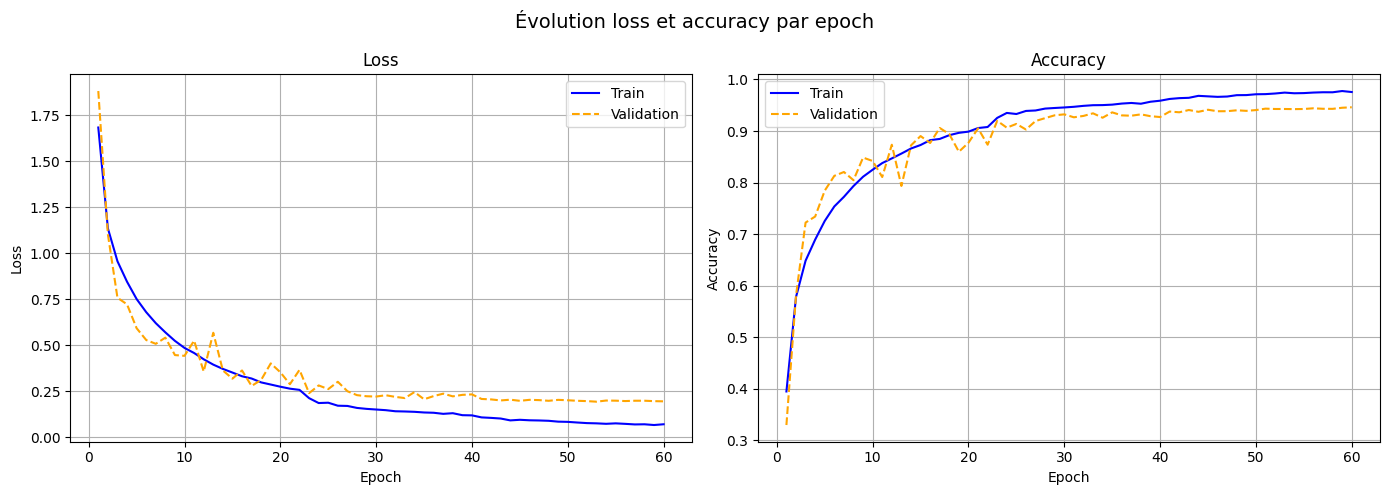

In [16]:
import matplotlib.pyplot as plt
# Visualisation de la variation de Loss et Accuracy entre train et val
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_loss     = history.history['loss']
val_loss       = history.history['val_loss']
train_accuracy = history.history['accuracy']
val_accuracy   = history.history['val_accuracy']
epochs         = range(1, len(train_loss) + 1)

axes[0].plot(epochs, train_loss, label='Train',      color='blue')
axes[0].plot(epochs, val_loss,   label='Validation', color='orange', linestyle='--')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)


axes[1].plot(epochs, train_accuracy, label='Train',      color='blue')
axes[1].plot(epochs, val_accuracy,   label='Validation', color='orange', linestyle='--')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('Évolution loss et accuracy par epoch', fontsize=14)
plt.tight_layout()
plt.show()

In [17]:
# Evaluation
test_loss, test_accuracy = model.evaluate(test_ds)
print(f"Accuracy test : {test_accuracy:.2%}")

66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 200ms/step - accuracy: 0.9301 - loss: 0.2426
Accuracy test : 93.01%


## Pourquoi RAF-DB est meilleur que FER-2013

FER-2013 souffre de deux problèmes majeurs :

  * **Déséquilibre des classes** — le nombre d'images par émotion est très inégal.
  Le modèle apprend à prédire `happy` et `neutral` bien mieux que `disgust`
  parce qu'il a beaucoup plus d'exemples pour ces classes.



* Qualité des annotations : FER-2013 vs RAF-DB

      ### FER-2013 — annotation automatique

      Les labels ont été assignés par un algorithme, pas par des humains.
      Le processus consistait à collecter des images depuis le web et à utiliser
      les métadonnées et mots clés associés pour deviner l'émotion.

      Le problème : un algorithme ne comprend pas le contexte ni les nuances.

      - Une personne qui pleure de joie   → algorithme dit "sad"   ✗
      - Une personne qui sourit avec peur → algorithme dit "happy" ✗
      - Une expression ambiguë            → algorithme choisit quand même une classe ✗

      Résultat : environ 20-30% de labels incorrects ou ambigus,
      ce qui plafonne la performance du modèle autour de 64%.

      ### RAF-DB — annotation manuelle par consensus humain

      Chaque image a été montrée à plusieurs annotateurs humains qui ont voté :

      - Si consensus → label assigné avec confiance
      - Si désaccord → image écartée ou marquée comme ambiguë

      Un humain comprend le contexte, les nuances et les expressions ambiguës
      ce qu'un algorithme ne peut pas faire.

      Résultat : labels fiables, modèle qui converge plus vite
      et atteint une meilleure accuracy.

RAF-DB résout les deux problèmes :
- Même nombre d'images par émotion grâce à l'augmentation de données
  (visible dans la structure : fichiers aug_XXXXXX.png)
- Labels assignés par plusieurs annotateurs humains — bien plus fiables

Résultat : le modèle converge plus vite (epoch 11 vs epoch 42)
et atteint une meilleure accuracy (82% vs 64%).

## Pourquoi val_accuracy dépasse train_accuracy sur RAF-DB
    Ce comportement est inhabituel mais s'explique par deux raisons :
    
    Dropout — pendant l'entraînement 25% à 50% des neurones sont désactivés
    aléatoirement à chaque batch. Le modèle est donc artificiellement handicapé
    pendant le train. En validation le Dropout est désactivé — tous les neurones
    sont actifs, ce qui améliore les prédictions.

    Dataset équilibré et bien annoté — pendant l'entraînement le
    modèle voit aussi bien les images originales que les images
    augmentées aug_XXXXXX.png. Les images augmentées sont des
    transformations artificielles — rotations, flips, zooms — qui
    peuvent être plus difficiles à classifier que les images
    originales. Le val set lui contient principalement des images
    originales propres et naturelles, ce qui le rend
    intrinsèquement plus facile à classifier correctement.






In [18]:
# Chargement du modèle
model_rafdb   = tf.keras.models.load_model(model_path)

In [19]:
for index , layer in enumerate(model_rafdb.layers) :
  print(f'{index} : {layer.name} : {layer.__class__.__name__}')

0 : conv2d : Conv2D
1 : batch_normalization : BatchNormalization
2 : activation : Activation
3 : max_pooling2d : MaxPooling2D
4 : dropout : Dropout
5 : conv2d_1 : Conv2D
6 : batch_normalization_1 : BatchNormalization
7 : activation_1 : Activation
8 : max_pooling2d_1 : MaxPooling2D
9 : dropout_1 : Dropout
10 : conv2d_2 : Conv2D
11 : batch_normalization_2 : BatchNormalization
12 : activation_2 : Activation
13 : max_pooling2d_2 : MaxPooling2D
14 : dropout_2 : Dropout
15 : conv2d_3 : Conv2D
16 : batch_normalization_3 : BatchNormalization
17 : activation_3 : Activation
18 : max_pooling2d_3 : MaxPooling2D
19 : dropout_3 : Dropout
20 : flatten : Flatten
21 : dense : Dense
22 : batch_normalization_4 : BatchNormalization
23 : dropout_4 : Dropout
24 : dense_1 : Dense


In [20]:
# Récupérer la 1 ère couche de convolution
conv2d = model_rafdb.layers[0]

# Récupérer les filtres et les biais
filters, biases = conv2d.get_weights()

# Vérification des shapes
print("Shape des filtres : " , filters.shape)
print("Shape des biais : " , biases.shape)

Shape des filtres :  (3, 3, 1, 32)
Shape des biais :  (32,)


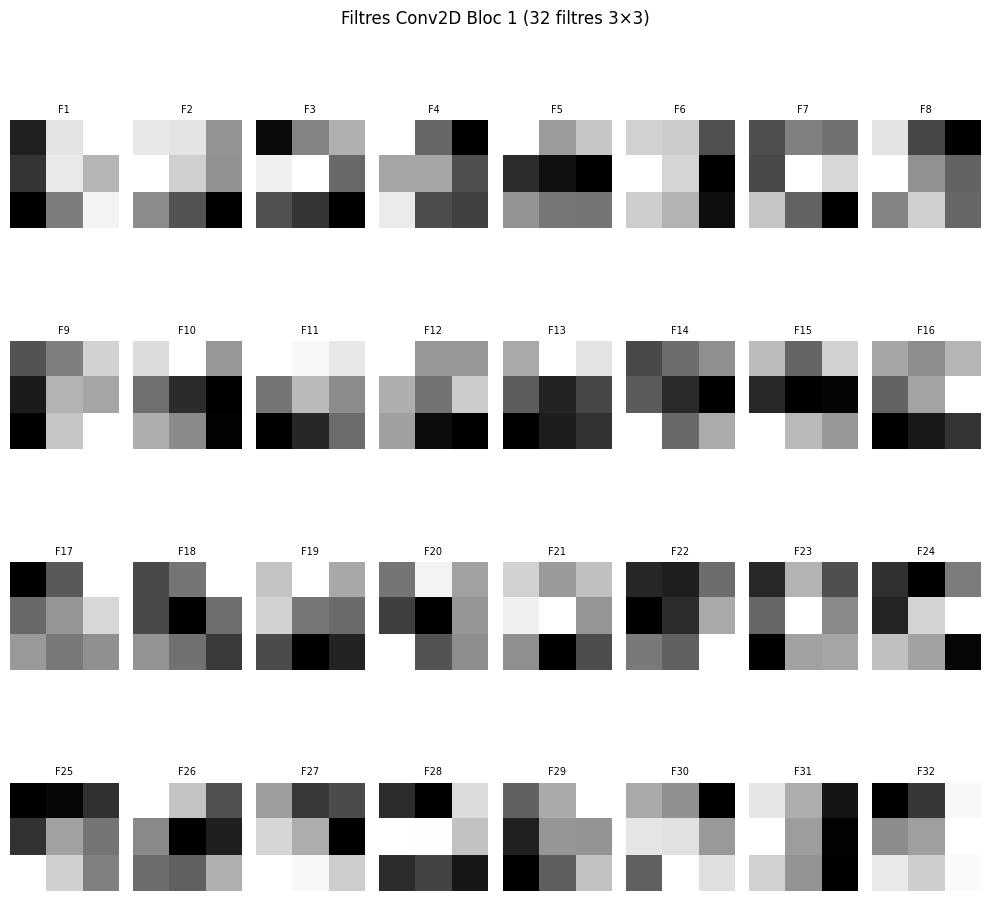

In [21]:
import matplotlib.pyplot as plt

# Crée une figure de 10×10 pouces divisée en 4 lignes et 8 colonnes
# → 32 sous-figures pour afficher les 32 filtres du bloc 1
fig, axes = plt.subplots(4, 8, figsize=(10, 10))

# axes est un tableau 2D (4, 8) — axes.flat le convertit en itérateur 1D
# enumerate donne (0, ax0), (1, ax1), ... (31, ax31)
for i, ax in enumerate(axes.flat):

    # Extrait le filtre i : toutes les lignes, toutes les colonnes, canal 0
    # résultat : tableau 2D (3, 3) représentant la grille de valeurs du filtre
    ax.imshow(filters[:, :, 0, i], cmap='gray')

    # Désactive les axes (graduation, bordures) pour un affichage plus propre
    ax.axis('off')

    # Titre local de chaque sous-figure : F1, F2, ... F32
    ax.set_title(f'F{i+1}', fontsize=7)

# Titre global au-dessus de toute la figure
plt.suptitle('Filtres Conv2D Bloc 1 (32 filtres 3×3)')

# Ajuste automatiquement les espacements entre sous-figures
# pour éviter les chevauchements entre titres et images
plt.tight_layout()

plt.show()


In [22]:
# Récupérer la 2 ème couche de convolution
conv2d_1 = model_rafdb.layers[5]

# Récupérer les filtres et les biais
filters, biases = conv2d_1.get_weights()

# Vérification des shapes
print("Shape des filtres : " , filters.shape)
print("Shape des biais : " , biases.shape)


Shape des filtres :  (3, 3, 32, 64)
Shape des biais :  (64,)


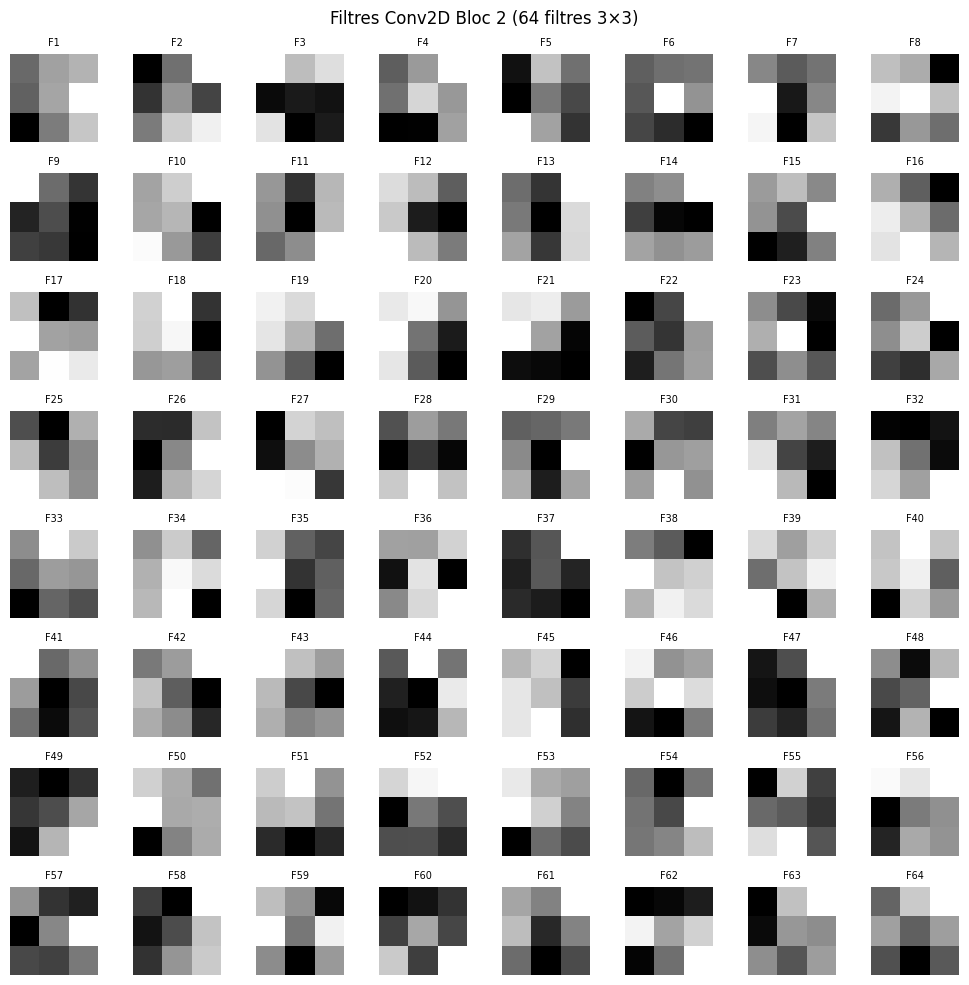

In [23]:
fig, axes = plt.subplots(8,8, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    # Récupérer le canal 0
    ax.imshow(filters[:, :, 0, i], cmap='gray')
    ax.axis('off')
    ax.set_title(f'F{i+1}', fontsize=7)

plt.suptitle('Filtres Conv2D Bloc 2 (64 filtres 3×3)')
plt.tight_layout()
plt.show()

In [25]:
# Récupérer la 3 ème couche de convolution
conv2d_2 = model_rafdb.layers[10]

# Récupérer les filtres et les biais
filters, biases = conv2d_2.get_weights()

# Vérification des shapes
print("Shape des filtres : " , filters.shape)
print("Shape des biais : " , biases.shape)

Shape des filtres :  (3, 3, 64, 128)
Shape des biais :  (128,)


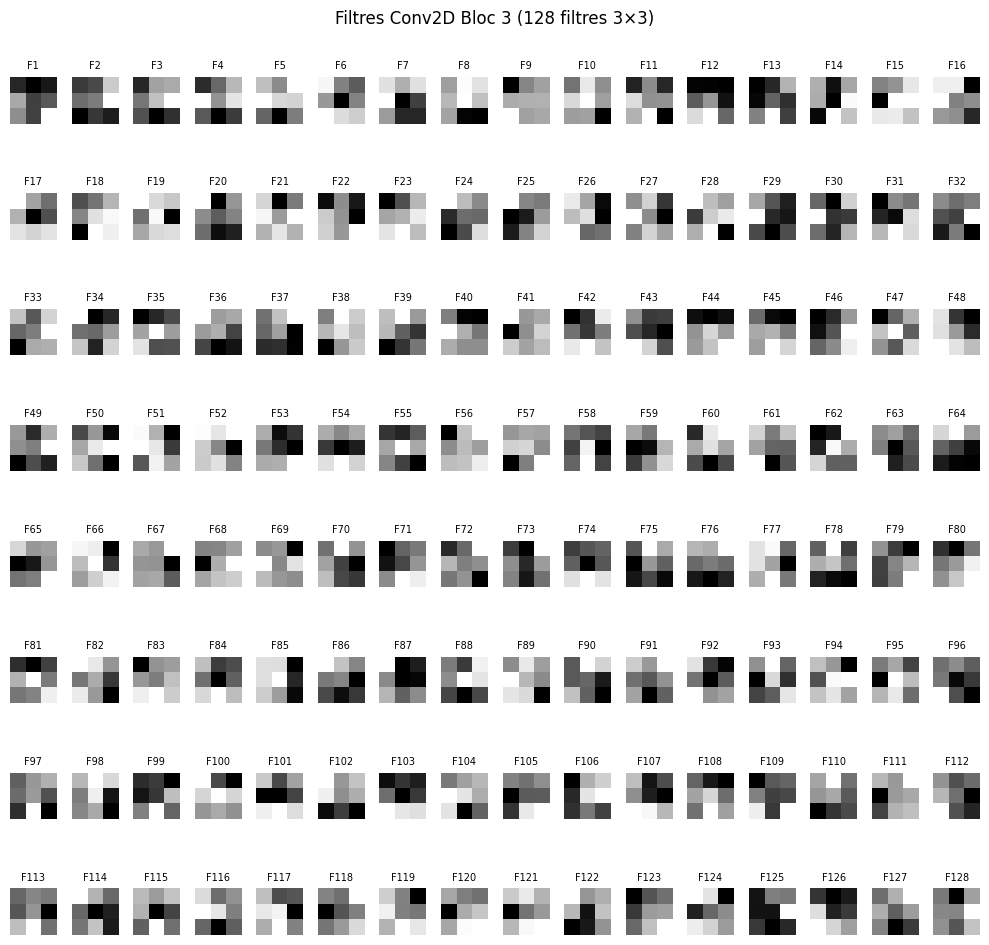

In [26]:
fig, axes = plt.subplots(8,16, figsize=(10, 10) )

for i, ax in enumerate(axes.flat):
    ax.imshow(filters[:, :, 0, i], cmap='gray')
    ax.axis('off')
    ax.set_title(f'F{i+1}', fontsize=7)

plt.suptitle('Filtres Conv2D Bloc 3 (128 filtres 3×3)')
plt.tight_layout()
plt.show()

In [27]:
# Récupérer la 4 ème couche de convolution
conv2d_3 = model_rafdb.layers[15]

# Récupérer les filtres et les biais
filters, biases = conv2d_3.get_weights()

# Vérification des shapes
print("Shape des filtres : " , filters.shape)
print("Shape des biais : " , biases.shape)

Shape des filtres :  (3, 3, 128, 256)
Shape des biais :  (256,)


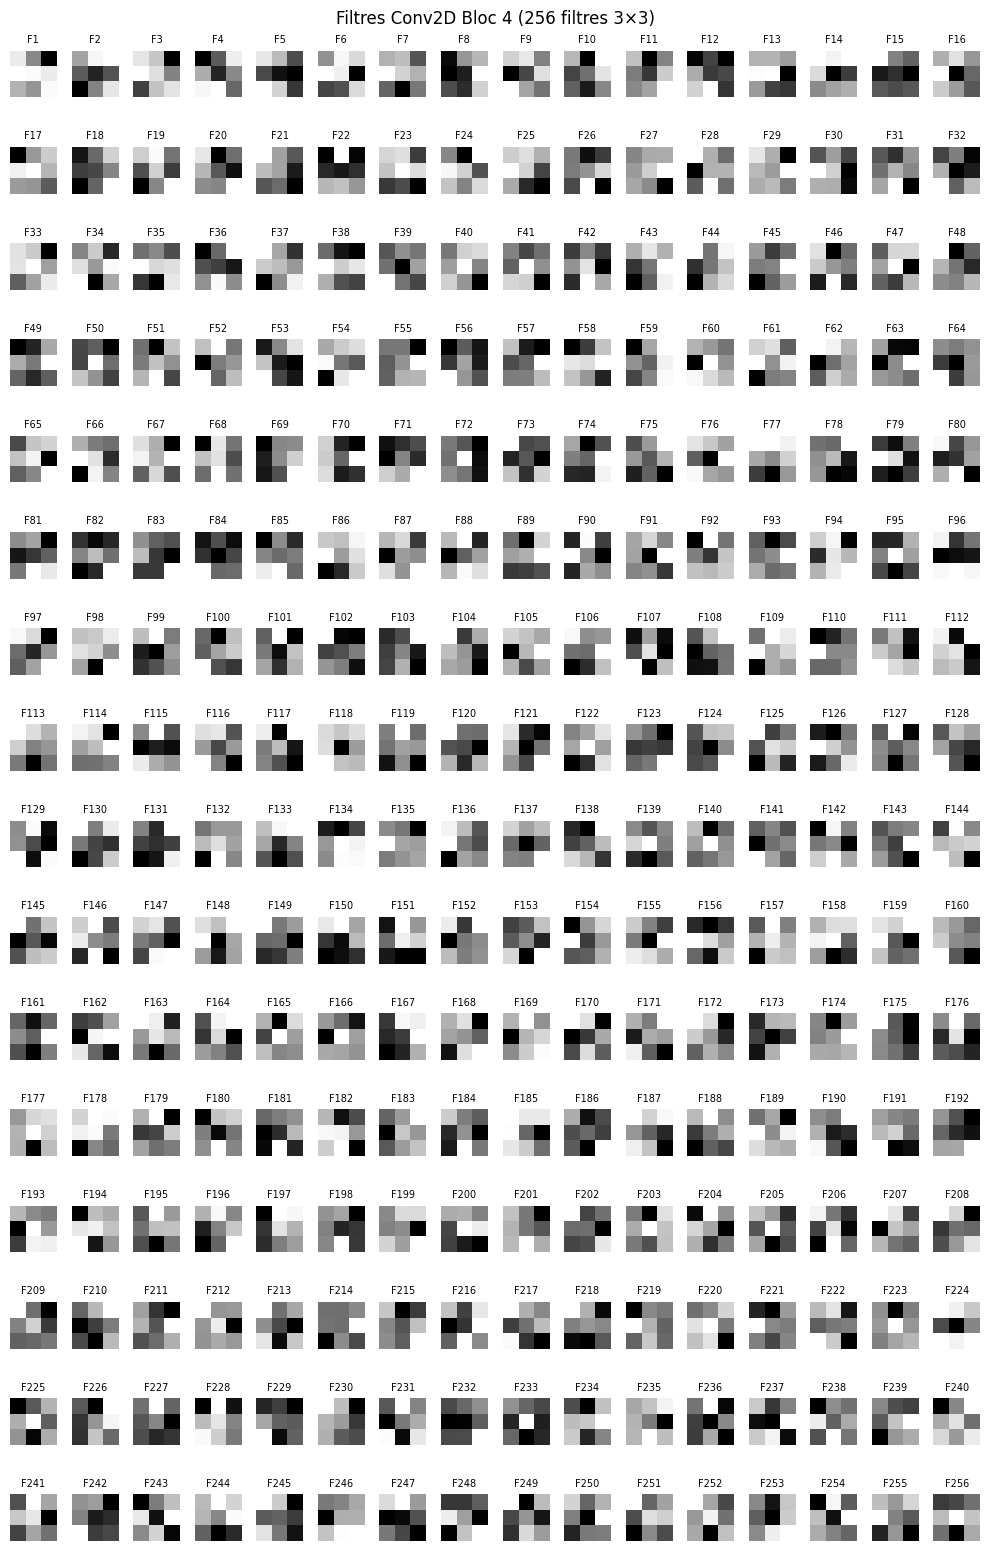

In [28]:
fig, axes = plt.subplots(16,16, figsize=(10, 16) )

for i, ax in enumerate(axes.flat):
    ax.imshow(filters[:, :, 0, i], cmap='gray')
    ax.axis('off')
    ax.set_title(f'F{i+1}', fontsize=7)

plt.suptitle('Filtres Conv2D Bloc 4 (256 filtres 3×3)')
plt.tight_layout()
plt.show()

In [29]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Matrice de confusion

y_true = np.concatenate(
    [np.argmax(labels , axis = 1 )
     for _, labels in test_ds]
)

y_pred = np.argmax(model_rafdb.predict(test_ds) , axis = 1 )

cm = confusion_matrix(y_true, y_pred)

66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 184ms/step


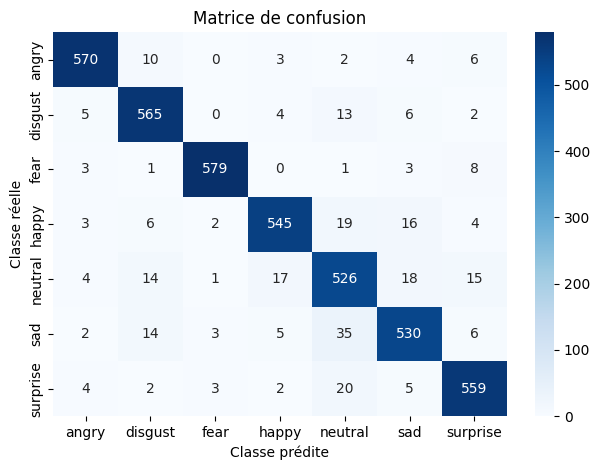

In [30]:
import seaborn as sns

EMOTION_LABELS = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

sns.heatmap(
    cm,
    annot=True,          # affiche les valeurs dans chaque cellule
    fmt='d',             # format entier
    cmap='Blues',        # palette de couleurs
    xticklabels=EMOTION_LABELS,
    yticklabels=EMOTION_LABELS
)
plt.title('Matrice de confusion')
plt.xlabel('Classe prédite')
plt.ylabel('Classe réelle')
plt.tight_layout()
plt.show()

In [32]:
# Resauvegarder en format H5 (plus compatible)
model.save(os.path.join(base_path,'models/best_model_rafdb.h5'))